# Checkpoint 03 — Modelagem Matemática e Computacional
**2º Semestre/2026 — Prof. Roberto G. Beraldo**

## Integrantes

| Nome | RM |
|------|----|
| _Davi Q. Zuolo_ | _RM571669_ |
| _Kayo Henderson_ | _RM570706_ |
| _Gustavo Zagato_ | _RM569420_ |
| _Daniel Vilela Mana_ | _RM571632_ |

---

**Área escolhida:** Ciência de Dados
**Aplicação:** Regressão Linear Múltipla para prever o preço de apartamentos, modelada como um sistema linear $A\,x = b$ (resolvido pelo método dos Mínimos Quadrados).

## Pergunta 1 — Aplicação escolhida e referências

### Contexto
Em Ciência de Dados, um dos modelos mais usados é a **Regressão Linear Múltipla**. Ela tenta explicar uma variável alvo (por exemplo, o **preço de um imóvel**) como uma combinação linear de variáveis explicativas (*features*), como **área**, **número de quartos** e **distância até o metrô**:

$$
\text{preço}_i \approx \beta_0 + \beta_1\,\text{área}_i + \beta_2\,\text{quartos}_i + \beta_3\,\text{distância}_i
$$

Escrevendo essa equação para cada um dos $m$ imóveis do conjunto de dados, obtemos um **sistema de equações lineares**:

$$
\underbrace{\begin{bmatrix}
1 & \text{área}_1 & \text{quartos}_1 & \text{dist}_1\\
1 & \text{área}_2 & \text{quartos}_2 & \text{dist}_2\\
\vdots & \vdots & \vdots & \vdots\\
1 & \text{área}_m & \text{quartos}_m & \text{dist}_m
\end{bmatrix}}_{A\ (m\times 4)}
\underbrace{\begin{bmatrix}\beta_0\\ \beta_1\\ \beta_2\\ \beta_3\end{bmatrix}}_{x\ (4\times 1)}
=
\underbrace{\begin{bmatrix}\text{preço}_1\\ \text{preço}_2\\ \vdots\\ \text{preço}_m\end{bmatrix}}_{b\ (m\times 1)}
$$

Na prática, há **muito mais observações (linhas) do que parâmetros (colunas)**, ou seja, $m > n$: o sistema é **sobredeterminado**. Como os dados reais têm ruído, normalmente não existe um $x$ que satisfaça todas as equações ao mesmo tempo. Por isso, busca-se o $x$ que **minimiza o erro quadrático** $\|Ax - b\|^2$ (método dos **Mínimos Quadrados**). Esse $x$ é solução de outro sistema linear, quadrado, chamado de **equações normais**:

$$
A^T A\, x = A^T b
$$

Ou seja, a regressão linear é, em essência, a resolução de sistemas do tipo $Ax=b$.

### Referências
1. BOYD, Stephen; VANDENBERGHE, Lieven. *Introduction to Applied Linear Algebra – Vectors, Matrices, and Least Squares*. Cambridge University Press, 2018. Capítulos 12 (*Least squares*) e 13 (*Least squares data fitting*). Disponível em: <https://web.stanford.edu/~boyd/vmls/> (PDF: <https://web.stanford.edu/~boyd/vmls/vmls.pdf>).
2. JAMES, G.; WITTEN, D.; HASTIE, T.; TIBSHIRANI, R.; TAYLOR, J. *An Introduction to Statistical Learning (with Applications in Python)*. Springer, 2023. Capítulo 3 (*Linear Regression*). Disponível em: <https://www.statlearning.com/>.
3. WIKIPEDIA. *Linear least squares*. Disponível em: <https://en.wikipedia.org/wiki/Linear_least_squares>.
4. NUMPY. *numpy.linalg.lstsq — NumPy Manual*. Disponível em: <https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html>.

## Pergunta 2 — Significado de $A$, $x$ e $b$

### Matriz $A$ (matriz de *design* / matriz de *features*), dimensão $m \times n$
Cada **linha** é um imóvel (uma observação do dataset) e cada **coluna** é uma característica:

| Coluna de $A$ | Significado | Unidade |
|---|---|---|
| 1ª coluna (todos iguais a 1) | Permite o termo independente (intercepto) $\beta_0$ | adimensional |
| 2ª coluna | Área útil do apartamento | m² |
| 3ª coluna | Número de quartos | quartos (contagem) |
| 4ª coluna | Distância até a estação de metrô mais próxima | km |

Os coeficientes $a_{ij}$ são, portanto, **os dados medidos/observados** de cada imóvel.

### Vetor de incógnitas $x$ (parâmetros do modelo), dimensão $n \times 1$

| Incógnita | Significado | Unidade |
|---|---|---|
| $\beta_0$ | Intercepto: preço "base" do modelo | R\$ mil |
| $\beta_1$ | Quanto o preço varia a cada m² a mais (mantidas as demais variáveis) | R\$ mil / m² |
| $\beta_2$ | Quanto o preço varia a cada quarto a mais | R\$ mil / quarto |
| $\beta_3$ | Quanto o preço varia a cada km a mais de distância do metrô (espera-se valor negativo) | R\$ mil / km |

### Vetor de termos constantes $b$ (variável alvo / *target*), dimensão $m \times 1$
São os **preços de venda observados** de cada imóvel, em **R\$ mil**.

### Quando resolvemos o sistema, o que obtemos?
Obtemos os **coeficientes do modelo de regressão** ($\beta_0, \beta_1, \beta_2, \beta_3$), isto é, o modelo "treinado".

Cada $\beta_j$ é uma **taxa marginal**: mostra o impacto de cada característica no preço. Por exemplo, $\beta_1 = 8{,}5$ significaria que, mantendo quartos e distância fixos, cada m² adicional aumenta o preço em cerca de R\$ 8.500. Com os coeficientes, também é possível **prever** o preço de um imóvel novo, calculando $\hat{y} = a_{\text{novo}}^T\,x$.

**Há unidades de medida?** Sim, e elas são consistentes (análise dimensional). Em cada termo $a_{ij}\,x_j$ o resultado precisa estar em **R\$ mil**, que é a unidade de $b$:
- (adimensional) × (R\$ mil) = R\$ mil
- (m²) × (R\$ mil / m²) = R\$ mil
- (quartos) × (R\$ mil / quarto) = R\$ mil
- (km) × (R\$ mil / km) = R\$ mil

O vetor de **resíduos** $r = b - Ax$ também está em R\$ mil e representa o erro de previsão do modelo para cada imóvel.

## Pergunta 3 — Exemplo numérico em Python

**Dados:** usamos um conjunto **ilustrativo** com 12 apartamentos. Os valores foram criados para fins didáticos, com ordens de grandeza plausíveis para o mercado, e com uma variação (ruído) nos preços, como acontece com dados reais.

### 3.1 Importação de bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

### 3.2 Montagem dos componentes do sistema como arrays

In [2]:
# Features de cada apartamento (uma linha por imóvel)
area      = np.array([45, 60, 75, 52, 90, 110, 68, 120, 38, 85, 95, 130], dtype=float)  # m²
quartos   = np.array([ 1,  2,  2,  1,  3,   3,  2,   4,  1,  3,  2,   4], dtype=float)  # quantidade
distancia = np.array([0.5, 1.2, 0.8, 2.5, 1.5, 3.0, 2.0, 0.7, 1.0, 4.0, 2.2, 3.5])        # km até o metrô

# Vetor b: preço observado de cada apartamento (R$ mil)
b = np.array([590, 715, 890, 555, 1040, 1135, 785, 1380, 505, 880, 1020, 1340], dtype=float)

# Matriz A (m x n): coluna de 1s (intercepto) + features
A = np.column_stack([np.ones_like(area), area, quartos, distancia])

m, n = A.shape
print(f"A tem dimensão {m} x {n}  ->  {m} equações e {n} incógnitas")
print("\nMatriz A  [1 | área (m²) | quartos | distância (km)]:")
print(A)
print("\nVetor b (preço em R$ mil):")
print(b)

A tem dimensão 12 x 4  ->  12 equações e 4 incógnitas

Matriz A  [1 | área (m²) | quartos | distância (km)]:
[[  1.   45.    1.    0.5]
 [  1.   60.    2.    1.2]
 [  1.   75.    2.    0.8]
 [  1.   52.    1.    2.5]
 [  1.   90.    3.    1.5]
 [  1.  110.    3.    3. ]
 [  1.   68.    2.    2. ]
 [  1.  120.    4.    0.7]
 [  1.   38.    1.    1. ]
 [  1.   85.    3.    4. ]
 [  1.   95.    2.    2.2]
 [  1.  130.    4.    3.5]]

Vetor b (preço em R$ mil):
[ 590.  715.  890.  555. 1040. 1135.  785. 1380.  505.  880. 1020. 1340.]


### 3.3 Tentativa 1: resolver $Ax=b$ diretamente com `np.linalg.solve`

`np.linalg.solve` só resolve sistemas **quadrados** e com solução única. Como $A$ é $12 \times 4$, a chamada falha:

In [3]:
try:
    np.linalg.solve(A, b)
except np.linalg.LinAlgError as erro:
    print("np.linalg.solve falhou:", erro)

np.linalg.solve falhou: Last 2 dimensions of the array must be square


### 3.4 O sistema tem solução exata? (Teorema de Rouché–Capelli)

Um sistema $Ax=b$ tem solução **se e somente se** $\text{posto}(A) = \text{posto}([A\,|\,b])$. Vamos verificar:

In [4]:
posto_A  = np.linalg.matrix_rank(A)
posto_Ab = np.linalg.matrix_rank(np.column_stack([A, b]))

print(f"posto(A)     = {posto_A}")
print(f"posto([A|b]) = {posto_Ab}")

if posto_A == posto_Ab:
    print("-> Sistema POSSÍVEL: existe solução exata.")
else:
    print("-> Sistema IMPOSSÍVEL (incompatível): NÃO existe x que satisfaça as 12 equações ao mesmo tempo.")
    print("   É necessário buscar uma solução APROXIMADA (mínimos quadrados).")

posto(A)     = 4
posto([A|b]) = 5
-> Sistema IMPOSSÍVEL (incompatível): NÃO existe x que satisfaça as 12 equações ao mesmo tempo.
   É necessário buscar uma solução APROXIMADA (mínimos quadrados).


### 3.5 Solução aproximada por Mínimos Quadrados

Vamos resolver de **duas formas** e conferir se dão o mesmo resultado:

1. **Equações normais:** montamos o sistema quadrado $(A^TA)\,x = A^Tb$ (dimensão $4\times4$) e resolvemos com `np.linalg.solve`.
2. **`np.linalg.lstsq`:** função do NumPy que minimiza $\|Ax-b\|^2$ diretamente, usando a decomposição SVD, que é numericamente mais estável.

In [5]:
# Forma 1: equações normais  (A^T A) x = A^T b
AtA = A.T @ A
Atb = A.T @ b
x_normal = np.linalg.solve(AtA, Atb)

print("Sistema das equações normais (4 x 4):")
print("A^T A =\n", AtA)
print("A^T b =", Atb)
print("\nx (equações normais) =", x_normal)

# Forma 2: np.linalg.lstsq
x_lstsq, soma_res2, posto, valores_singulares = np.linalg.lstsq(A, b, rcond=None)
print("x (np.linalg.lstsq)  =", x_lstsq)

print("\nAs duas soluções coincidem?", np.allclose(x_normal, x_lstsq))

Sistema das equações normais (4 x 4):
A^T A =
 [[   12.     968.      28.      22.9 ]
 [  968.   87772.    2586.    2011.5 ]
 [   28.    2586.      78.      58.7 ]
 [   22.9   2011.5     58.7     58.41]]
A^T b = [ 10835.  967580.   28515.   21712.5]

x (equações normais) = [162.7367   9.1837  36.7694 -45.2923]
x (np.linalg.lstsq)  = [162.7367   9.1837  36.7694 -45.2923]

As duas soluções coincidem? True


In [6]:
nomes    = ["β0 (intercepto)", "β1 (área)", "β2 (quartos)", "β3 (distância)"]
unidades = ["R$ mil", "R$ mil / m²", "R$ mil / quarto", "R$ mil / km"]

x = x_lstsq
print("Coeficientes do modelo de regressão:\n")
for nome, valor, unidade in zip(nomes, x, unidades):
    print(f"  {nome:<17} = {valor:9.3f}  {unidade}")

print("\nModelo ajustado:")
print(f"  preço ≈ {x[0]:.2f} + {x[1]:.2f}·área + {x[2]:.2f}·quartos {x[3]:+.2f}·distância   (R$ mil)")

Coeficientes do modelo de regressão:

  β0 (intercepto)   =   162.737  R$ mil
  β1 (área)         =     9.184  R$ mil / m²
  β2 (quartos)      =    36.769  R$ mil / quarto
  β3 (distância)    =   -45.292  R$ mil / km

Modelo ajustado:
  preço ≈ 162.74 + 9.18·área + 36.77·quartos -45.29·distância   (R$ mil)


### 3.6 Avaliação da solução: resíduos e qualidade do ajuste

In [7]:
b_previsto = A @ x
residuos   = b - b_previsto

print(f"{'Apto':>4} | {'Preço real':>10} | {'Previsto':>9} | {'Resíduo':>8}   (R$ mil)")
print("-" * 46)
for i, (real, prev, r) in enumerate(zip(b, b_previsto, residuos), start=1):
    print(f"{i:>4} | {real:>10.1f} | {prev:>9.1f} | {r:>8.1f}")

norma_residuo = np.linalg.norm(residuos)
rmse = np.sqrt(np.mean(residuos**2))
r2   = 1 - np.sum(residuos**2) / np.sum((b - b.mean())**2)

print(f"\n||b - Ax||  = {norma_residuo:.3f} R$ mil   (≠ 0, logo a solução NÃO é exata)")
print(f"RMSE        = {rmse:.3f} R$ mil   (erro médio de previsão)")
print(f"R²          = {r2:.4f}            (fração da variação do preço explicada pelo modelo)")

Apto | Preço real |  Previsto |  Resíduo   (R$ mil)
----------------------------------------------
   1 |      590.0 |     590.1 |     -0.1
   2 |      715.0 |     732.9 |    -17.9
   3 |      890.0 |     888.8 |      1.2
   4 |      555.0 |     563.8 |     -8.8
   5 |     1040.0 |    1031.6 |      8.4
   6 |     1135.0 |    1147.4 |    -12.4
   7 |      785.0 |     770.2 |     14.8
   8 |     1380.0 |    1380.2 |     -0.2
   9 |      505.0 |     503.2 |      1.8
  10 |      880.0 |     872.5 |      7.5
  11 |     1020.0 |    1009.1 |     10.9
  12 |     1340.0 |    1345.2 |     -5.2

||b - Ax||  = 32.398 R$ mil   (≠ 0, logo a solução NÃO é exata)
RMSE        = 9.352 R$ mil   (erro médio de previsão)
R²          = 0.9989            (fração da variação do preço explicada pelo modelo)


### 3.7 Validações matemáticas

Testes automáticos para confirmar que a solução encontrada é, de fato, a solução de mínimos quadrados:
- As duas formas de cálculo devem coincidir.
- O resíduo deve ser **ortogonal** às colunas de $A$, ou seja, $A^T r = 0$. Essa é a condição geométrica do mínimo: $Ax$ é a projeção de $b$ sobre o espaço coluna de $A$.
- A soma dos quadrados dos resíduos deve bater com o valor devolvido por `lstsq`.
- Qualquer perturbação em $x$ deve **aumentar** o erro.

In [8]:
# 1) As duas formas coincidem
assert np.allclose(x_normal, x_lstsq)

# 2) Ortogonalidade do resíduo: A^T r ≈ 0
print("A^T r =", A.T @ residuos)
assert np.allclose(A.T @ residuos, 0, atol=1e-6)

# 3) Soma dos quadrados dos resíduos confere com o lstsq
assert np.isclose(np.sum(residuos**2), soma_res2[0])

# 4) x é ótimo: perturbações aleatórias sempre aumentam ||Ax - b||
rng = np.random.default_rng(42)
erro_otimo = np.linalg.norm(A @ x - b)
for _ in range(1000):
    x_perturbado = x + rng.normal(scale=0.5, size=n)
    assert np.linalg.norm(A @ x_perturbado - b) >= erro_otimo

# 5) Matriz A tem posto completo
print(f"posto(A) = {posto} (posto completo = {n})")
print(f"número de condição de A = {np.linalg.cond(A):.1f}")
assert posto == n

print("\nTodas as validações passaram ✔")

A^T r = [-0. -0. -0. -0.]
posto(A) = 4 (posto completo = 4)
número de condição de A = 298.9

Todas as validações passaram ✔


### 3.8 Comparação: e se usássemos só 4 apartamentos?

Com apenas 4 imóveis teríamos um sistema **quadrado** $4 \times 4$. Se a matriz for invertível, há **solução exata** (resíduo zero). Porém o modelo passaria exatamente pelos 4 pontos escolhidos, incluindo seu ruído, e os coeficientes mudariam muito conforme a escolha dos imóveis. Isso mostra por que, em Ciência de Dados, preferimos usar **todos os dados** e aceitar uma solução aproximada.

In [9]:
for linhas in ([0, 1, 4, 7], [2, 3, 8, 11]):
    A4, b4 = A[linhas], b[linhas]
    x4 = np.linalg.solve(A4, b4)            # sistema quadrado -> solução exata
    print(f"Aptos {[i + 1 for i in linhas]}:  det(A4) = {np.linalg.det(A4):9.2f}")
    print(f"   x exato = {x4}")
    print(f"   resíduo nos 4 aptos usados  = {np.linalg.norm(A4 @ x4 - b4):.2e}  (exato)")
    print(f"   RMSE nos 12 aptos           = {np.sqrt(np.mean((A @ x4 - b)**2)):.2f} R$ mil\n")

print(f"Mínimos quadrados com os 12 aptos: x = {x}")
print(f"   RMSE nos 12 aptos           = {rmse:.2f} R$ mil")

Aptos [1, 2, 5, 8]:  det(A4) =     16.50
   x exato = [ 73.1818  12.9697 -60.     -13.6364]
   resíduo nos 4 aptos usados  = 3.41e-13  (exato)
   RMSE nos 12 aptos           = 76.95 R$ mil

Aptos [3, 4, 9, 12]:  det(A4) =    -71.90
   x exato = [170.0834   8.8317  48.4075 -49.096 ]
   resíduo nos 4 aptos usados  = 5.68e-14  (exato)
   RMSE nos 12 aptos           = 11.13 R$ mil

Mínimos quadrados com os 12 aptos: x = [162.7367   9.1837  36.7694 -45.2923]
   RMSE nos 12 aptos           = 9.35 R$ mil


### 3.9 Usando o modelo: previsão para um imóvel novo

In [ ]:
# Apartamento novo: 80 m², 2 quartos, 1,8 km do metrô
novo = np.array([1, 80, 2, 1.8])
preco_previsto = novo @ x
valor_reais = f"{preco_previsto * 1000:,.0f}".replace(",", ".")   # separador de milhar no padrão brasileiro
print(f"Preço previsto para 80 m², 2 quartos, 1,8 km do metrô: R$ {valor_reais}")

Preço previsto para 80 m², 2 quartos, 1,8 km do metrô: R$ 889.444


### 3.10 Visualização

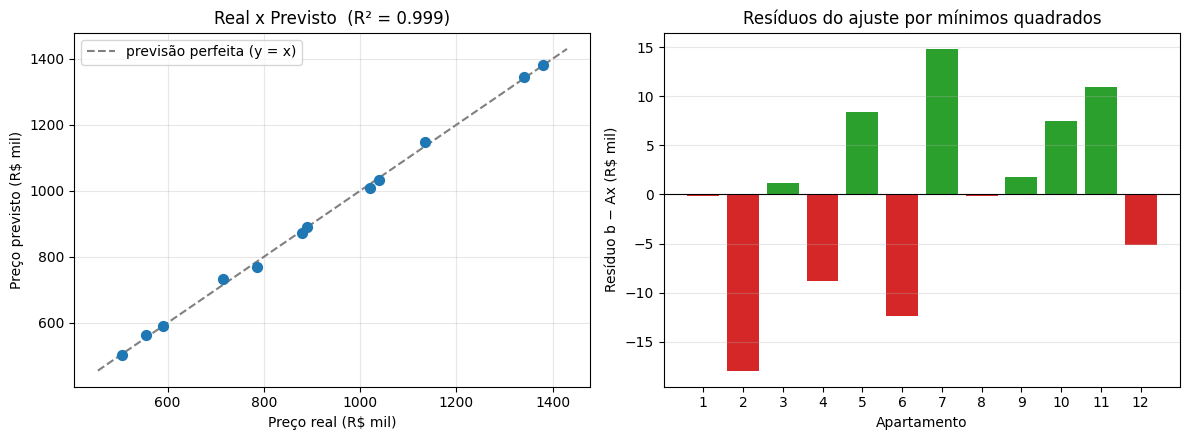

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Real x Previsto
ax1.scatter(b, b_previsto, color="#1f77b4", s=50, zorder=3)
limites = [b.min() - 50, b.max() + 50]
ax1.plot(limites, limites, "--", color="gray", label="previsão perfeita (y = x)")
ax1.set_xlabel("Preço real (R$ mil)")
ax1.set_ylabel("Preço previsto (R$ mil)")
ax1.set_title(f"Real x Previsto  (R² = {r2:.3f})")
ax1.legend()
ax1.grid(alpha=0.3)

# Resíduos por apartamento
ids = np.arange(1, m + 1)
ax2.bar(ids, residuos, color=np.where(residuos >= 0, "#2ca02c", "#d62728"))
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(ids)
ax2.set_xlabel("Apartamento")
ax2.set_ylabel("Resíduo b − Ax (R$ mil)")
ax2.set_title("Resíduos do ajuste por mínimos quadrados")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 3.11 Foi possível obter uma solução exata? — Resposta e justificativa

**Não. Foi necessário obter uma solução aproximada**, pelo método dos **Mínimos Quadrados**.

**Justificativa:**
1. **O sistema é sobredeterminado.** Há 12 equações (um apartamento por equação) e apenas 4 incógnitas ($\beta_0,\dots,\beta_3$). A matriz $A$ não é quadrada, então não tem inversa, e `np.linalg.solve(A, b)` falha.
2. **O sistema é incompatível.** Pelo teorema de Rouché–Capelli, $\text{posto}(A) = 4$ e $\text{posto}([A\,|\,b]) = 5$. Como os postos são diferentes, **não existe** nenhum vetor $x$ que satisfaça as 12 equações simultaneamente. Isso acontece porque os preços reais têm ruído e dependem de fatores que o modelo não captura (andar, vaga de garagem, estado de conservação etc.). Nenhum hiperplano passa exatamente por todos os pontos.
3. **A solução de mínimos quadrados é a melhor aproximação possível.** Ela minimiza $\|Ax-b\|^2$ e é a solução **exata** do sistema quadrado das equações normais $A^TA\,x = A^Tb$. As validações mostraram que o resíduo é ortogonal às colunas de $A$ ($A^Tr \approx 0$) e que qualquer perturbação em $x$ aumenta o erro. O resíduo final é diferente de zero, o que confirma que a solução é aproximada. Mesmo assim, o ajuste é muito bom ($R^2$ próximo de 1 e RMSE pequeno em relação aos preços).
4. **Solução exata não é desejável aqui.** Na seção 3.8, com apenas 4 apartamentos, o sistema $4\times4$ teve solução exata. Porém os coeficientes mudaram bastante conforme os imóveis escolhidos. Com os apartamentos 1, 2, 5 e 8, por exemplo, o coeficiente de quartos ficou **negativo** (cada quarto a mais *reduziria* o preço), o que não faz sentido, e o RMSE nos 12 apartamentos subiu para cerca de R\$ 77 mil. Nos dois casos, o erro sobre o conjunto completo foi maior que o da solução de mínimos quadrados. Em Ciência de Dados, usar mais dados e aceitar uma solução aproximada gera modelos mais confiáveis e que generalizam melhor.